# Proyecto Final — Matemáticas Discretas con Aplicaciones
## Red de Bicicletas Compartidas LOBOBICI — Ciudad Universitaria (BUAP)

### Sección 1: Definición, Clasificación y Visualización
- **Datos dinámicos:** Todos los grafos, propiedades y visualizaciones se construyen dinámicamente a partir de `data/estaciones_cu.csv` y `data/aristas_cu.csv`.
- Si modificas un nodo, un peso o el estado abierto/cerrado en los CSV (o en memoria durante la demo), basta con volver a ejecutar las celdas para actualizar toda la red y el modelo bipartito.

In [1]:
import csv
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines

# ============================================================
# 1. CARGA DINÁMICA DEL GRAFO BASE G = (V, E) DESDE LOS CSV
# ============================================================
G = nx.Graph()

with open("data/estaciones_cu.csv", encoding="utf-8") as f:
    for row in csv.DictReader(f):
        nid = int(row["id"])
        G.add_node(
            nid,
            nombre=row["nombre"],
            lat=float(row["lat"]),
            lon=float(row["lon"]),
            pos=(float(row["x_m"]), float(row["y_m"])),
            abierta=bool(int(row["abierta_1530"])),
            bicis=int(row["bicis_1530"]),
        )

with open("data/aristas_cu.csv", encoding="utf-8") as f:
    for row in csv.DictReader(f):
        G.add_edge(
            int(row["origen"]),
            int(row["destino"]),
            dist_euclidiana_m=float(row["dist_euclidiana_m"]),
            dist_ruta_m=float(row["dist_ruta_m"]),
            fuente_ruta=row["fuente_ruta"],
        )

# ============================================================
# 2. VERIFICACIÓN DINÁMICA DE CLASIFICACIÓN TEÓRICA
# ============================================================
n_nodos = G.number_of_nodes()
n_aristas = G.number_of_edges()
lazos = nx.number_of_selfloops(G)
es_simple = (lazos == 0) and (not G.is_multigraph())
grados = dict(G.degree())
suma_grados = sum(grados.values())
abiertas = [n for n, d in G.nodes(data=True) if d["abierta"]]
cerradas = [n for n, d in G.nodes(data=True) if not d["abierta"]]
total_bicis = sum(d["bicis"] for _, d in G.nodes(data=True))

print("=== RESUMEN Y CLASIFICACIÓN TEÓRICA DE G = (V, E) ===")
print(f"Vértices |V|            : {n_nodos} (requisito >= 15: {'OK' if n_nodos >= 15 else 'NO'})")
print(f"Aristas  |E|            : {n_aristas} (requisito >= 22: {'OK' if n_aristas >= 22 else 'NO'})")
print(f"Dirigido                : {G.is_directed()} (No dirigido)")
print(f"Multigrafo              : {G.is_multigraph()}")
print(f"Lazos (self-loops)      : {lazos}")
print(f"Grafo simple            : {es_simple}")
print(f"Conexo                  : {nx.is_connected(G)} (componentes: {nx.number_connected_components(G)})")
print(f"Ponderado               : Sí (peso principal: dist_ruta_m en metros)")
print(f"Lema apretón de manos   : sum(deg) = {suma_grados} == 2|E| = {2 * n_aristas} -> {suma_grados == 2 * n_aristas}")
print(f"Grado mín / máx / prom  : {min(grados.values())} / {max(grados.values())} / {np.mean(list(grados.values())):.2f}")
print(f"Corte 15:30 hrs         : {len(abiertas)} abiertas ({total_bicis} bicis) | {len(cerradas)} cerradas")

=== RESUMEN Y CLASIFICACIÓN TEÓRICA DE G = (V, E) ===
Vértices |V|            : 21 (requisito >= 15: OK)
Aristas  |E|            : 29 (requisito >= 22: OK)
Dirigido                : False (No dirigido)
Multigrafo              : False
Lazos (self-loops)      : 0
Grafo simple            : True
Conexo                  : True (componentes: 1)
Ponderado               : Sí (peso principal: dist_ruta_m en metros)
Lema apretón de manos   : sum(deg) = 58 == 2|E| = 58 -> True
Grado mín / máx / prom  : 1 / 5 / 2.76
Corte 15:30 hrs         : 8 abiertas (356 bicis) | 13 cerradas


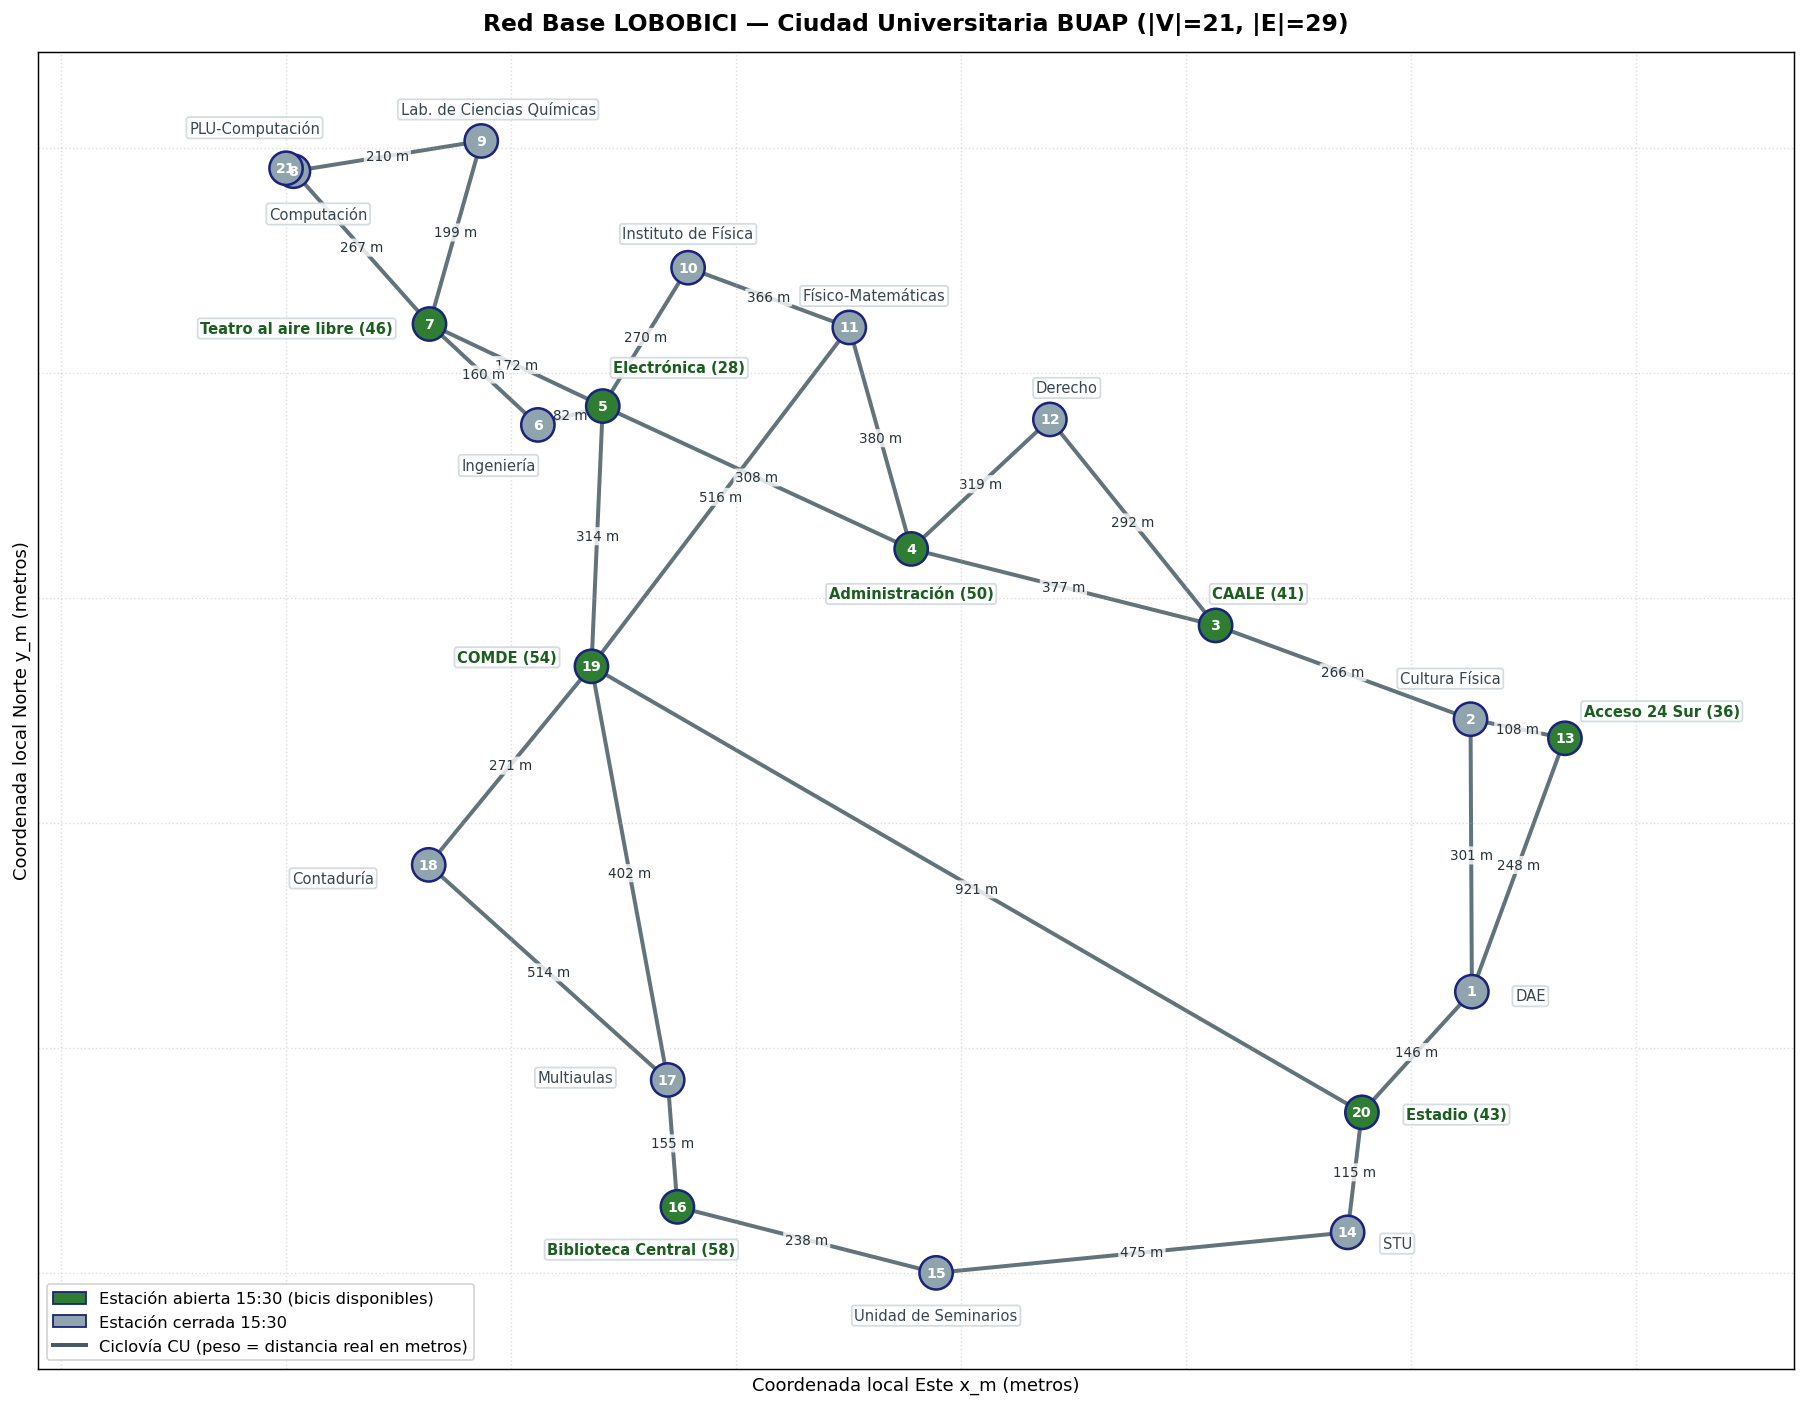

In [2]:
# ============================================================
# VISUALIZACIÓN DE LA RED BASE LOBOBICI CU (MATPLOTLIB + NETWORKX)
# ============================================================
pos = nx.get_node_attributes(G, "pos")

# Desplazamientos finos de etiquetas (dx, dy en metros) para evitar empalmes
label_offsets = {
    1:  (52,  -4),
    2:  (-18, 36),
    3:  (38,  28),
    4:  (0,  -40),
    5:  (68,  34),
    6:  (-35,-36),
    7:  (-118,-4),
    8:  (22, -38),
    9:  (15,  28),
    10: (0,   30),
    11: (22,  28),
    12: (15,  28),
    13: (86,  24),
    14: (44, -10),
    15: (0,  -38),
    16: (-32,-38),
    17: (-82,  2),
    18: (-85,-12),
    19: (-75,  8),
    20: (84,  -2),
    21: (-28, 36),
}

fig, ax = plt.subplots(figsize=(14, 11), dpi=130)

# Aristas
nx.draw_networkx_edges(
    G, pos, ax=ax,
    edge_color="#455A64",
    width=2.2,
    alpha=0.85,
)

# Pesos de aristas (distancia real por ciclovía en metros)
edge_labels = {(u, v): f"{d['dist_ruta_m']:.0f} m" for u, v, d in G.edges(data=True)}
nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_size=7.5,
    font_color="#263238",
    rotate=False,
    bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none", alpha=0.8),
    ax=ax,
)

# Nodos coloreados dinámicamente según estado a las 15:30
node_colors = ["#2E7D32" if G.nodes[n]["abierta"] else "#90A4AE" for n in G.nodes()]
nx.draw_networkx_nodes(
    G, pos, ax=ax,
    node_color=node_colors,
    edgecolors="#1A237E",
    linewidths=1.4,
    node_size=340,
)

# Número de estación dentro del nodo
nx.draw_networkx_labels(
    G, pos, ax=ax,
    font_size=7.8,
    font_weight="bold",
    font_color="white",
)

# Nombres claros junto a cada estación
for nid, (x, y) in pos.items():
    dx, dy = label_offsets.get(nid, (18, 18))
    nombre = G.nodes[nid]["nombre"]
    if G.nodes[nid]["abierta"]:
        texto = f"{nombre} ({G.nodes[nid]['bicis']})"
        color_txt = "#1B5E20"
    else:
        texto = nombre
        color_txt = "#37474F"
    ax.text(
        x + dx, y + dy, texto,
        fontsize=8.2,
        fontweight="semibold" if G.nodes[nid]["abierta"] else "normal",
        color=color_txt,
        ha="center",
        va="center",
        bbox=dict(boxstyle="round,pad=0.18", facecolor="white", edgecolor="#CFD8DC", alpha=0.88),
    )

# Leyenda y formato
legend_items = [
    mpatches.Patch(facecolor="#2E7D32", edgecolor="#1A237E", label="Estación abierta 15:30 (bicis disponibles)"),
    mpatches.Patch(facecolor="#90A4AE", edgecolor="#1A237E", label="Estación cerrada 15:30"),
    mlines.Line2D([], [], color="#455A64", linewidth=2.2, label="Ciclovía CU (peso = distancia real en metros)"),
]
ax.legend(handles=legend_items, loc="lower left", frameon=True, fontsize=9)
ax.set_title(
    f"Red Base LOBOBICI — Ciudad Universitaria BUAP (|V|={G.number_of_nodes()}, |E|={G.number_of_edges()})",
    fontsize=13, fontweight="bold", pad=12,
)
ax.set_xlabel("Coordenada local Este x_m (metros)", fontsize=10)
ax.set_ylabel("Coordenada local Norte y_m (metros)", fontsize=10)
ax.set_aspect("equal")
ax.set_xlim(-220, 1340)
ax.set_ylim(-85, 1085)
ax.grid(True, linestyle=":", alpha=0.4)
plt.tight_layout()
plt.show()

=== VALIDACIÓN DEL MODELO BIPARTITO B = (U ∪ W, E_B) ===
|U| (Abiertas / Oferta)   : 8
|W| (Cerradas / Demanda)  : 13
|E_B| (Asignaciones K=2) : 26
nx.is_bipartite(B)        : True
Aristas dentro de U o W   : 0 en U, 0 en W
¿Existen ciclos impares?  : False (ciclos base encontrados: 6)

--- Asignación de cobertura (Cerrada -> Abierta principal / respaldo) ---
   1 DAE                        -> #1 20-Estadio (146 m) | #2 13-Acceso 24 Sur (248 m)
   2 Cultura Física             -> #1 13-Acceso 24 Sur (108 m) | #2 3-CAALE (266 m)
   6 Ingeniería                 -> #1 5-Electrónica (82 m) | #2 7-Teatro al aire libre (160 m)
   8 Computación                -> #1 7-Teatro al aire libre (267 m) | #2 5-Electrónica (440 m)
   9 Lab. de Ciencias Químicas  -> #1 7-Teatro al aire libre (199 m) | #2 5-Electrónica (371 m)
  10 Instituto de Física        -> #1 5-Electrónica (270 m) | #2 7-Teatro al aire libre (442 m)
  11 Físico-Matemáticas         -> #1 4-Administración (380 m) | #2 19-COMDE (516 m)

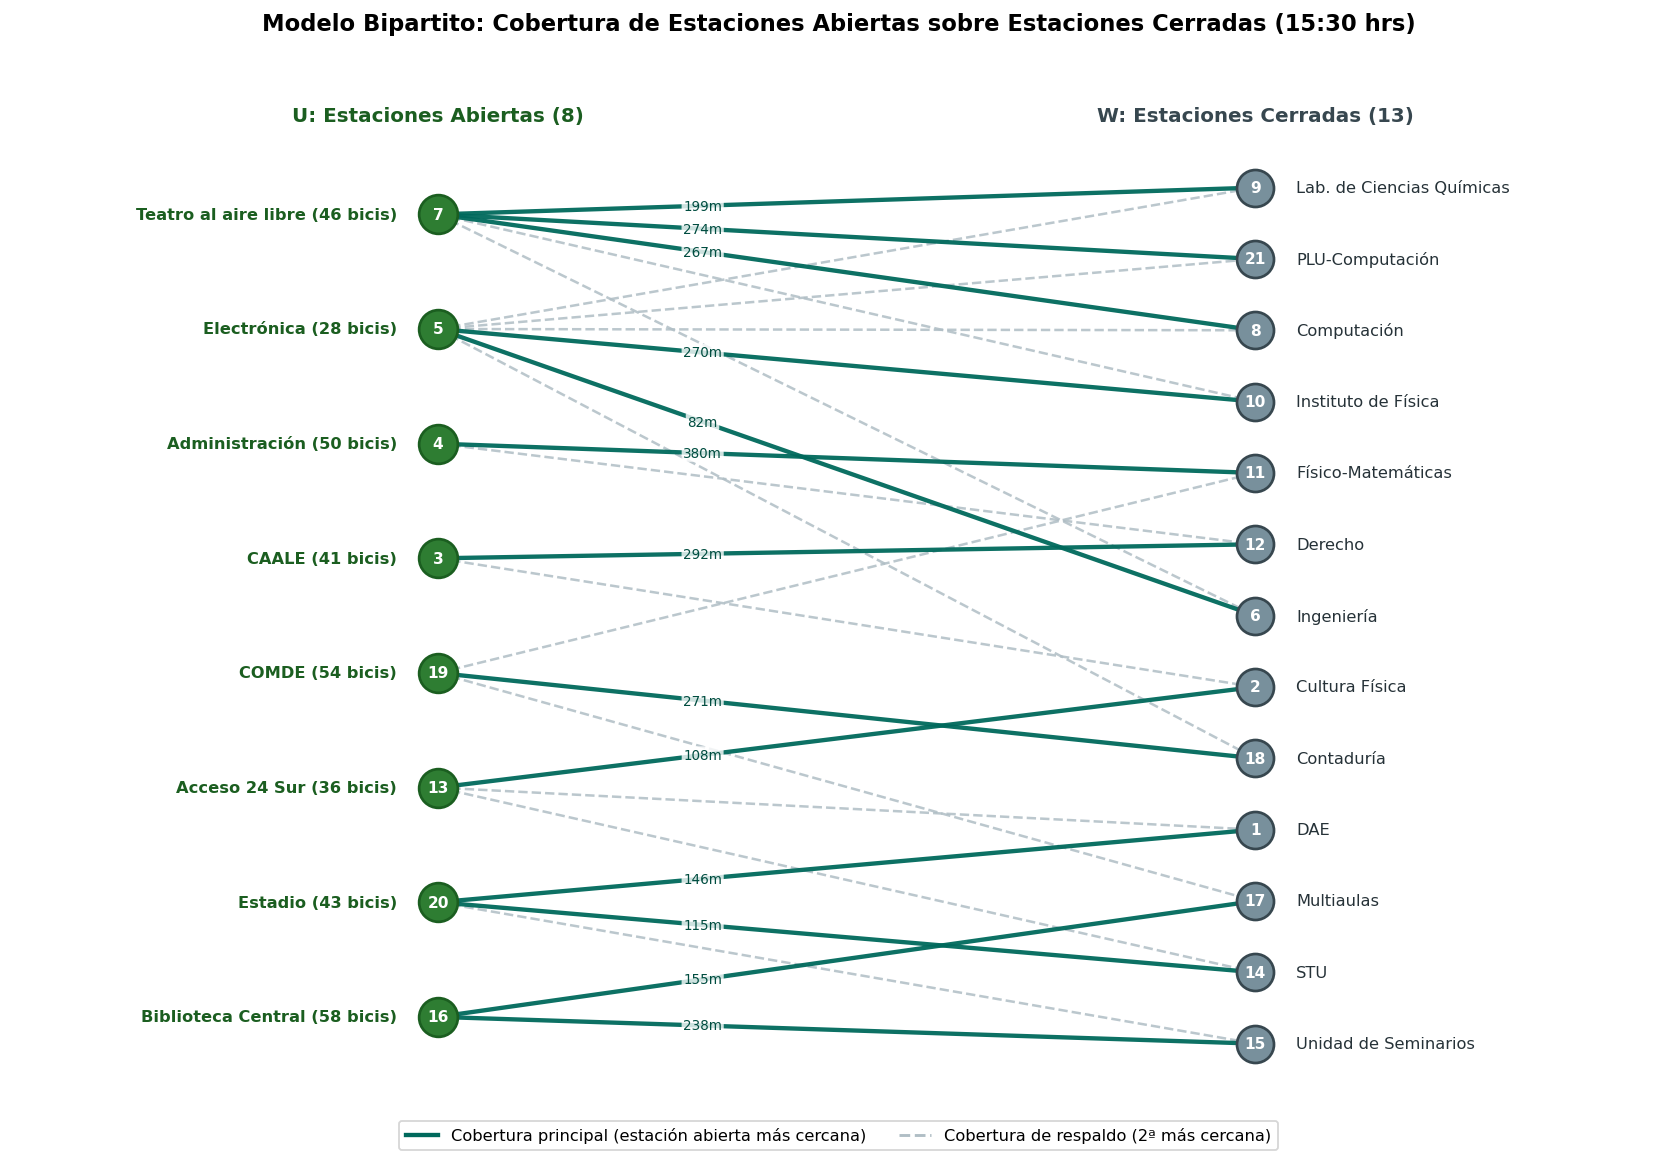

In [3]:
# ============================================================
# MODELO BIPARTITO DINÁMICO B = (U ∪ W, E_B)
# U = Estaciones ABIERTAS (oferta / servidores activos a las 15:30)
# W = Estaciones CERRADAS (demanda a reasignar)
# E_B = Asignación de cada estación cerrada a sus K estaciones abiertas
#       más cercanas según la distancia real por ciclovía (Dijkstra en G)
# ============================================================
K_OPCIONES = 2  # 1 = solo la más cercana, 2 = principal + respaldo

U = sorted([n for n, d in G.nodes(data=True) if d["abierta"]])
W = sorted([n for n, d in G.nodes(data=True) if not d["abierta"]])

B = nx.Graph()
for u in U:
    B.add_node(u, bipartite=0, nombre=G.nodes[u]["nombre"], bicis=G.nodes[u]["bicis"])
for w in W:
    B.add_node(w, bipartite=1, nombre=G.nodes[w]["nombre"], bicis=0)

# Cálculo dinámico de distancias más cortas en G (Dijkstra)
for w in W:
    distancias = nx.single_source_dijkstra_path_length(G, w, weight="dist_ruta_m")
    candidatas = sorted([(distancias[u], u) for u in U if u in distancias])
    for prioridad, (dist_m, u) in enumerate(candidatas[:K_OPCIONES], start=1):
        B.add_edge(u, w, dist_ruta_m=round(dist_m, 1), prioridad=prioridad)

# --- Validación analítica / computacional de bipartición ---
es_bipartito = nx.is_bipartite(B)
aristas_internas_U = [(a, b) for a, b in B.edges() if a in U and b in U]
aristas_internas_W = [(a, b) for a, b in B.edges() if a in W and b in W]
ciclos_base = nx.cycle_basis(B)
hay_ciclo_impar = any(len(c) % 2 == 1 for c in ciclos_base)

print("=== VALIDACIÓN DEL MODELO BIPARTITO B = (U ∪ W, E_B) ===")
print(f"|U| (Abiertas / Oferta)   : {len(U)}")
print(f"|W| (Cerradas / Demanda)  : {len(W)}")
print(f"|E_B| (Asignaciones K={K_OPCIONES}) : {B.number_of_edges()}")
print(f"nx.is_bipartite(B)        : {es_bipartito}")
print(f"Aristas dentro de U o W   : {len(aristas_internas_U)} en U, {len(aristas_internas_W)} en W")
print(f"¿Existen ciclos impares?  : {hay_ciclo_impar} (ciclos base encontrados: {len(ciclos_base)})")

print("\n--- Asignación de cobertura (Cerrada -> Abierta principal / respaldo) ---")
for w in W:
    vecinas = sorted(B[w].items(), key=lambda item: item[1]["prioridad"])
    resumen = " | ".join(
        f"#{d['prioridad']} {u}-{G.nodes[u]['nombre']} ({d['dist_ruta_m']:.0f} m)"
        for u, d in vecinas
    )
    print(f"  {w:2d} {G.nodes[w]['nombre']:26s} -> {resumen}")

# --- Visualización del grafo bipartito en dos columnas ---
# Ordenamos cada columna de Norte a Sur (mayor y_m arriba) para reducir cruces
U_ord = sorted(U, key=lambda n: G.nodes[n]["pos"][1], reverse=True)
W_ord = sorted(W, key=lambda n: G.nodes[n]["pos"][1], reverse=True)

pos_B = {}
y_U = np.linspace(0.95, 0.05, len(U_ord))
y_W = np.linspace(0.98, 0.02, len(W_ord))
for u, y in zip(U_ord, y_U):
    pos_B[u] = (0.0, y)
for w, y in zip(W_ord, y_W):
    pos_B[w] = (1.0, y)

fig, ax = plt.subplots(figsize=(13, 9), dpi=130)

aristas_p1 = [(u, v) for u, v, d in B.edges(data=True) if d["prioridad"] == 1]
aristas_p2 = [(u, v) for u, v, d in B.edges(data=True) if d["prioridad"] == 2]

nx.draw_networkx_edges(B, pos_B, edgelist=aristas_p2, edge_color="#B0BEC5", width=1.4, style="--", alpha=0.85, ax=ax)
nx.draw_networkx_edges(B, pos_B, edgelist=aristas_p1, edge_color="#00695C", width=2.4, alpha=0.95, ax=ax)

# Etiquetas de distancia sobre aristas principales (prioridad 1)
labels_p1 = {(u, v): f"{B[u][v]['dist_ruta_m']:.0f}m" for u, v in aristas_p1}
nx.draw_networkx_edge_labels(
    B, pos_B,
    edge_labels=labels_p1,
    label_pos=0.32,
    font_size=7.5,
    font_color="#004D40",
    rotate=False,
    bbox=dict(boxstyle="round,pad=0.12", facecolor="white", edgecolor="none", alpha=0.8),
    ax=ax,
)

nx.draw_networkx_nodes(B, pos_B, nodelist=U_ord, node_color="#2E7D32", edgecolors="#1B5E20", node_size=460, linewidths=1.5, ax=ax)
nx.draw_networkx_nodes(B, pos_B, nodelist=W_ord, node_color="#78909C", edgecolors="#37474F", node_size=420, linewidths=1.5, ax=ax)
nx.draw_networkx_labels(B, pos_B, font_size=8.5, font_weight="bold", font_color="white", ax=ax)

# Nombres claros afuera de cada columna
for u in U_ord:
    x, y = pos_B[u]
    ax.text(
        x - 0.05, y,
        f"{G.nodes[u]['nombre']} ({G.nodes[u]['bicis']} bicis)",
        ha="right", va="center", fontsize=9, fontweight="semibold", color="#1B5E20",
    )
for w in W_ord:
    x, y = pos_B[w]
    ax.text(
        x + 0.05, y,
        G.nodes[w]["nombre"],
        ha="left", va="center", fontsize=9, color="#263238",
    )

ax.text(0.0, 1.05, "U: Estaciones Abiertas (8)", ha="center", va="bottom", fontsize=11, fontweight="bold", color="#1B5E20")
ax.text(1.0, 1.05, "W: Estaciones Cerradas (13)", ha="center", va="bottom", fontsize=11, fontweight="bold", color="#37474F")

legend_B = [
    mlines.Line2D([], [], color="#00695C", linewidth=2.4, label="Cobertura principal (estación abierta más cercana)"),
    mlines.Line2D([], [], color="#B0BEC5", linewidth=1.6, linestyle="--", label="Cobertura de respaldo (2ª más cercana)"),
]
ax.legend(handles=legend_B, loc="lower center", bbox_to_anchor=(0.5, -0.06), ncol=2, frameon=True, fontsize=9)
ax.set_title("Modelo Bipartito: Cobertura de Estaciones Abiertas sobre Estaciones Cerradas (15:30 hrs)", fontsize=12.5, fontweight="bold", pad=28)
ax.set_xlim(-0.52, 1.50)
ax.set_ylim(-0.04, 1.10)
ax.axis("off")
plt.tight_layout()
plt.show()